In [ ]:
import seaborn as sns
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
df = sns.load_dataset("penguins")

In [ ]:
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [ ]:
df.dropna(axis=0,inplace=True)
df.reset_index(drop=True,inplace=True)

In [ ]:
df.isna().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [ ]:
x = df.iloc[:,2:-1]
y = df.iloc[:,0]

In [ ]:
encoder_species = LabelEncoder()
y = encoder_species.fit_transform(y)

In [ ]:
# x.sex = LabelEncoder().fit_transform(x.sex)
# x.island = LabelEncoder().fit_transform(x.island)

In [ ]:
x

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,36.7,19.3,193.0,3450.0
4,39.3,20.6,190.0,3650.0
...,...,...,...,...
328,47.2,13.7,214.0,4925.0
329,46.8,14.3,215.0,4850.0
330,50.4,15.7,222.0,5750.0
331,45.2,14.8,212.0,5200.0


In [ ]:
x_train,x_test, y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
model = Sequential([
    Dense(32,activation= "relu",input_shape=(4,)),
    Dense(16,activation= "relu"),
    Dense(4,activation= "relu"),
    Dense(3,activation= "softmax")
])


In [ ]:
model.compile(
    optimizer= "adam",
    loss= "sparse_categorical_crossentropy",
    metrics= ["accuracy"]
)

In [ ]:
history = model.fit(
    x_train,
    y_train,
    batch_size = 16,
    epochs = 100,
    validation_data = (x_test,y_test),
    verbose = 1
)

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.5526 - loss: 0.8706 - val_accuracy: 0.7910 - val_loss: 0.7389
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7895 - loss: 0.6631 - val_accuracy: 0.8060 - val_loss: 0.5533
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7932 - loss: 0.5093 - val_accuracy: 0.8060 - val_loss: 0.4246
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7932 - loss: 0.4101 - val_accuracy: 0.8060 - val_loss: 0.3450
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8120 - loss: 0.3541 - val_accuracy: 0.8955 - val_loss: 0.3024
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8534 - loss: 0.3206 - val_accuracy: 0.9403 - val_loss: 0.2785
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8759 - loss: 0.2978 - val_accuracy: 0.9552 - val_loss: 0.2616
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9098 - loss: 0.2812 - val_accuracy: 0.9701 

In [ ]:
import matplotlib.pyplot as plt

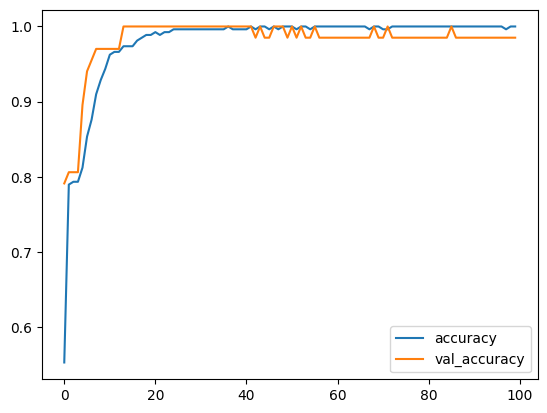

In [ ]:
plt.plot(history.history['accuracy'], label = 'accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.legend()

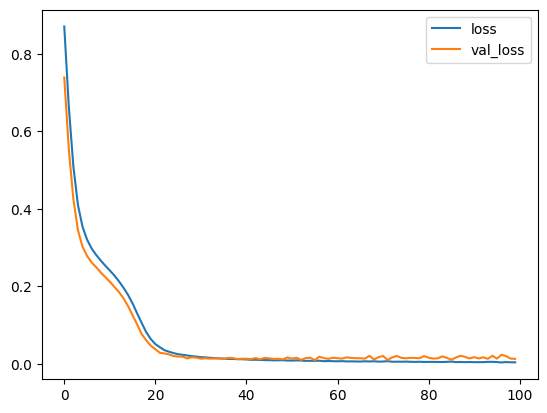

In [ ]:
plt.plot(history.history['loss'],label = 'loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.legend()